# BAN 8101 Predictive Analytics
## Week 4: Logistic Regression & Classification Metrics

### Week 4 Big Question
**How can we predict the probability of an event and turn that probability into a useful decision?**

This week, we move to **classification**.

Examples:
- Will a customer churn?
- Will a borrower default?
- Will a transaction be fraudulent?
- Will a customer respond to a campaign?

Our workflow becomes:

**Data → Probability → Threshold → Class Prediction → Evaluation**

# 1. Regression vs. Classification

### Regression
Predicts a **continuous value**.

Examples:
- House price
- Sales revenue
- Steering angle

### Classification
Predicts a **category** or the **probability of belonging to a category**.

Examples:
- Churn / No Churn
- Fraud / Not Fraud
- Default / No Default
- Obstacle / No Obstacle

A logistic regression model first estimates a probability.

For example:

`P(Churn = 1) = 0.78`

A decision rule then converts that probability into a class prediction.

# 2. Our Example: Customer Churn

We will use a **synthetic customer churn dataset** created inside this notebook.

Why synthetic?

- It requires no external download.
- Everyone receives exactly the same data.
- We can intentionally include realistic issues such as missing values and categorical variables.
- The variables have business-friendly interpretations.

Our target:
- `Churn = 1` → customer leaves
- `Churn = 0` → customer stays

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay, classification_report,
    roc_auc_score, RocCurveDisplay
)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("Libraries loaded successfully.")

Libraries loaded successfully.


# 3. Create the Dataset

The following cell creates 2,000 fictional customers.

| Variable | Type | Description |
|---|---|---|
| `tenure_months` | Numeric | Number of months the customer has been with the company. A larger value means the customer has had a longer relationship with the company. |
| `monthly_charge` | Numeric | The amount the customer is charged each month for the service. Higher monthly charges may influence customer satisfaction and churn behavior. |
| `support_tickets` | Numeric | Number of recent customer-service or technical-support requests made by the customer. A large number of support tickets may indicate service problems or customer dissatisfaction. |
| `usage_change_pct` | Numeric | Percentage change in the customer's recent service usage. A negative value means usage has decreased, while a positive value means usage has increased. A large decline in usage may indicate that the customer is becoming less engaged with the service. |
| `contract_type` | Categorical | Type of contract the customer currently has. In our example, customers may have a **Month-to-month**, **One year**, or **Two year** contract. Contract length may influence how easily or how likely a customer is to leave. |
| `autopay` | Categorical | Indicates whether the customer has automatic payment enabled. Values are **Yes** or **No**. Customers using autopay may behave differently from customers who manually make payments each month. |
| `Churn` | Binary target | Indicates whether the customer leaves the company. `1 = Churn` and `0 = Stay`. This is the variable we are trying to predict. |

In [2]:
# ---------------------------------------------------------
# Create a synthetic customer churn dataset
# ---------------------------------------------------------

# Number of customers to simulate
n = 2000


# ---------------------------------------------------------
# 1. Generate predictor variables
# ---------------------------------------------------------

# Customer tenure:
# Generate an integer between 1 and 72 months.
# Example: 1 means the customer is very new,
# while 72 means the customer has been with the company for 6 years.
tenure_months = rng.integers(1, 73, n)


# Monthly charge:
# Generate values from a normal distribution with:
# mean = 75
# standard deviation = 20
#
# np.clip() forces all values to stay between $20 and $150.
monthly_charge = np.clip(
    rng.normal(75, 20, n),
    20,
    150
)


# Support tickets:
# Use a Poisson distribution because this is count data.
# The average number of tickets is approximately 1.8.
#
# np.clip() limits the number of tickets to between 0 and 10.
support_tickets = np.clip(
    rng.poisson(1.8, n),
    0,
    10
)


# Usage change:
# Represents the percentage change in customer usage.
#
# Mean = -2%, meaning usage slightly decreases on average.
# Standard deviation = 18 percentage points.
#
# Values are restricted to between -60% and +60%.
#
# Example:
# -25 means usage decreased by 25%
# +15 means usage increased by 15%
usage_change_pct = np.clip(
    rng.normal(-2, 18, n),
    -60,
    60
)


# Contract type:
# Randomly assign each customer to one of three contract types.
#
# Probabilities:
# 55% Month-to-month
# 25% One year
# 20% Two year
contract_type = rng.choice(
    ["Month-to-month", "One year", "Two year"],
    size=n,
    p=[0.55, 0.25, 0.20]
)


# Autopay:
# 62% of customers use automatic payment
# 38% do not
autopay = rng.choice(
    ["Yes", "No"],
    size=n,
    p=[0.62, 0.38]
)


# ---------------------------------------------------------
# 2. Create the underlying churn model
# ---------------------------------------------------------

# We now create a "logit" score.
#
# This is the linear part of a logistic regression model:
#
# logit = b0 + b1*x1 + b2*x2 + ... + bp*xp
#
# The coefficients below are intentionally chosen so that
# some customer characteristics increase churn risk while
# others decrease it.

logit = (

    # Intercept:
    # This provides a baseline churn tendency before
    # considering customer characteristics.
    -0.8

    # Tenure effect:
    # Each additional month of tenure REDUCES the log-odds of churn.
    #
    # Longer-term customers are therefore designed to be
    # less likely to churn in this synthetic dataset.
    - 0.035 * tenure_months

    # Monthly charge effect:
    # Customers paying more than the average level of $75
    # are given somewhat higher churn risk.
    #
    # Subtracting 75 centers the variable around $75.
    + 0.018 * (monthly_charge - 75)

    # Support ticket effect:
    # Each additional support ticket INCREASES churn risk.
    #
    # This is intended to represent the idea that customers
    # experiencing more problems may be more likely to leave.
    + 0.38 * support_tickets

    # Usage change effect:
    # The coefficient is negative.
    #
    # Therefore:
    # - Increasing usage reduces churn risk
    # - Decreasing usage increases churn risk
    #
    # Example:
    # usage_change_pct = -20
    # -0.025 * (-20) = +0.50
    #
    # So declining usage increases the logit and therefore
    # increases predicted churn probability.
    - 0.025 * usage_change_pct

    # Month-to-month contract:
    # Customers on month-to-month contracts receive a
    # positive adjustment, increasing churn risk.
    + 0.90 * (contract_type == "Month-to-month")

    # Two-year contract:
    # Customers on two-year contracts receive a negative
    # adjustment, reducing churn risk.
    - 0.45 * (contract_type == "Two year")

    # One-year contracts receive no additional adjustment here,
    # so they effectively serve as the reference category.

    # Autopay:
    # Customers who do NOT use autopay receive a positive
    # adjustment, increasing churn risk.
    + 0.45 * (autopay == "No")
)


# ---------------------------------------------------------
# 3. Convert the logit score into a probability
# ---------------------------------------------------------

# Logistic regression uses the sigmoid / logistic function:
#
# probability = 1 / (1 + exp(-logit))
#
# This transformation guarantees that the result falls
# between 0 and 1.
prob_churn = 1 / (1 + np.exp(-logit))


# ---------------------------------------------------------
# 4. Generate the actual churn outcome
# ---------------------------------------------------------

# For each customer, generate either:
#
# 1 = Churn
# 0 = Stay
#
# The probability of getting a 1 is determined by prob_churn.
#
# Example:
# If prob_churn = 0.80, that customer has an 80% chance
# of being assigned Churn = 1.
churn = rng.binomial(
    1,
    prob_churn
)


# ---------------------------------------------------------
# 5. Combine everything into a pandas DataFrame
# ---------------------------------------------------------

df = pd.DataFrame({
    "tenure_months": tenure_months,
    "monthly_charge": monthly_charge.round(2),
    "support_tickets": support_tickets,
    "usage_change_pct": usage_change_pct.round(2),
    "contract_type": contract_type,
    "autopay": autopay,
    "Churn": churn
})


# Display the first five customers
df.head()

,tenure_months,monthly_charge,support_tickets,usage_change_pct,contract_type,autopay,Churn
0,7,60.16,2,-5.94,One year,No,0
1,56,93.49,1,2.28,Month-to-month,No,0
2,48,75.69,3,-15.95,Month-to-month,No,1
3,32,69.34,5,13.56,Month-to-month,Yes,1
4,32,72.88,1,-23.39,Two year,Yes,0


# 4. Introduce Realistic Data Problems

Real datasets are rarely perfectly clean.

We will intentionally add a small amount of missing data so that we can practice a reproducible preprocessing workflow.

In [3]:
df_dirty = df.copy()

for col in ["monthly_charge", "usage_change_pct", "contract_type"]:
    missing_idx = rng.choice(df_dirty.index, size=30, replace=False)
    df_dirty.loc[missing_idx, col] = np.nan

df_dirty.sample(8, random_state=RANDOM_STATE)

,tenure_months,monthly_charge,support_tickets,usage_change_pct,contract_type,autopay,Churn
1860,54,113.49,2,13.95,Month-to-month,Yes,1
353,32,59.79,1,1.98,Month-to-month,Yes,0
1333,59,65.20,0,20.32,Month-to-month,Yes,1
905,52,62.68,1,0.17,Month-to-month,Yes,0
1289,45,81.64,2,33.02,Month-to-month,No,1
1273,49,99.59,0,-32.73,Month-to-month,Yes,0
938,34,51.78,0,40.34,Two year,Yes,0
1731,66,82.86,3,-24.46,Month-to-month,No,0


# 5. Data Preparation

Before modeling, always ask:

1. What is the target?
2. What predictors are available?
3. Are there missing values?
4. Which variables are numeric?
5. Which variables are categorical?
6. Are the target classes balanced?

In [4]:
print("Shape:", df_dirty.shape)
print("\nData types:")
print(df_dirty.dtypes)

print("\nMissing values:")
print(df_dirty.isna().sum())

print("\nTarget distribution:")
print(df_dirty["Churn"].value_counts())

print("\nTarget proportions:")
print(df_dirty["Churn"].value_counts(normalize=True).round(3))

Shape: (2000, 7)

Data types:
tenure_months         int64
monthly_charge      float64
support_tickets       int64
usage_change_pct    float64
contract_type        object
autopay              object
Churn                 int64
dtype: object

Missing values:
tenure_months        0
monthly_charge      30
support_tickets      0
usage_change_pct    30
contract_type       30
autopay              0
Churn                0
dtype: int64

Target distribution:
Churn
0    1298
1     702
Name: count, dtype: int64

Target proportions:
Churn
0    0.649
1    0.351
Name: proportion, dtype: float64


### Discussion
- Is `Churn` continuous or categorical?
- Which variables are numeric?
- Which variables are categorical?
- What problems could occur if we ignore missing values?
- Is the target strongly imbalanced?

# 6. Define X and y

As in Week 3:
- `X` contains our predictors
- `y` contains our target

In [5]:
X = df_dirty.drop(columns="Churn")
y = df_dirty["Churn"]

print("Predictor columns:", list(X.columns))
print("Target name: Churn")

Predictor columns: ['tenure_months', 'monthly_charge', 'support_tickets', 'usage_change_pct', 'contract_type', 'autopay']
Target name: Churn


# 7. Train/Test Split

The model learns from the **training set**.

The **test set** is held back so we can evaluate performance on data the model did not use for training.

For classification, we will use `stratify=y` to preserve the class proportions.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training rows: 1600
Testing rows: 400

Training class proportions:
Churn
0    0.649
1    0.351
Name: proportion, dtype: float64

Testing class proportions:
Churn
0    0.65
1    0.35
Name: proportion, dtype: float64


# 8. Model 1 — Simple Logistic Regression

Our first model uses only **one predictor**:

`support_tickets`

Question:

> Can the number of recent support tickets help us predict whether a customer will churn?

In [7]:
X1_train = X_train[["support_tickets"]]
X1_test = X_test[["support_tickets"]]

model1 = LogisticRegression()
model1.fit(X1_train, y_train)

print("Intercept:", model1.intercept_[0])
print("Coefficient for support_tickets:", model1.coef_[0][0])

Intercept: -1.0807285390100567
Coefficient for support_tickets: 0.2564355827173621


## Interpreting the Coefficient

A positive coefficient means higher values of the predictor are associated with a **higher predicted probability** of the positive class.

Here, the positive class is `Churn = 1`.

A more intuitive quantity is the **odds ratio**:

`odds ratio = exp(coefficient)`

- Odds ratio > 1 → higher odds of the positive class
- Odds ratio < 1 → lower odds of the positive class

In [8]:
coef1 = model1.coef_[0][0]
odds_ratio1 = np.exp(coef1)

print("Coefficient:", round(coef1, 3))
print("Odds ratio:", round(odds_ratio1, 3))

Coefficient: 0.256
Odds ratio: 1.292


# 9. Predicted Probability Comes Before Predicted Class

Logistic regression first estimates:

`P(Churn = 1)`

At the default threshold of 0.50:
- Probability < 0.50 → predict 0
- Probability ≥ 0.50 → predict 1

In [9]:
prob1 = model1.predict_proba(X1_test)[:, 1]
pred1 = model1.predict(X1_test)

model1_results = pd.DataFrame({
    "support_tickets": X1_test["support_tickets"].values,
    "Actual_Churn": y_test.values,
    "Predicted_Probability": prob1,
    "Predicted_Class": pred1
})

model1_results.head(10).round(3)

,support_tickets,Actual_Churn,Predicted_Probability,Predicted_Class
0,3,0,0.423,0
1,2,1,0.362,0
2,2,0,0.362,0
3,3,0,0.423,0
4,3,1,0.423,0
5,0,0,0.253,0
6,2,0,0.362,0
7,0,1,0.253,0
8,4,0,0.486,0
9,1,0,0.305,0


# 10. Evaluating a Classification Model

After fitting a logistic regression model, we need to determine how well it performs on observations that were **not** used to train the model.

Unlike linear regression, where we compare predicted and actual numerical values, classification models produce class predictions such as:

$$
0=\text{Stay}
$$

and

$$
1=\text{Churn}
$$
For our customer churn example:

$$
\text{Positive Class}=1=\text{Churn}
$$

$$
\text{Negative Class}=0=\text{Stay}
$$

Before interpreting metrics such as accuracy, precision, recall, and F1 score, we first need to understand the **confusion matrix**.

---

## 10.1 Confusion Matrix

A confusion matrix compares the **actual outcome** with the **predicted outcome**.

| | Predicted Churn (1) | Predicted Stay (0) |
|---|---:|---:|
| **Actual Churn (1)** | True Positive (TP) | False Negative (FN) |
| **Actual Stay (0)** | False Positive (FP) | True Negative (TN) |

### True Positive (TP)

The customer actually churned, and the model correctly predicted churn.

$$
Actual=1,\quad Predicted=1
$$

### True Negative (TN)

The customer actually stayed, and the model correctly predicted stay.

$$
Actual=0,\quad Predicted=0
$$

### False Positive (FP)

The model predicted that the customer would churn, but the customer actually stayed.

$$
Actual=0,\quad Predicted=1
$$

This is a **false alarm**. For example, the company might unnecessarily send this customer a retention offer.

### False Negative (FN)

The model predicted that the customer would stay, but the customer actually churned.

$$
Actual=1,\quad Predicted=0
$$

This is a **missed churner**. The company may lose the customer without taking any retention action.

### Why does this matter?

A confusion matrix tells us **what kinds of mistakes the model is making**.

In a business problem, a false positive and a false negative may have very different costs.

For example:

- False positive → unnecessary retention offer
- False negative → customer leaves without intervention

---

## 10.2 Accuracy

Accuracy answers:

> **What proportion of all predictions were correct?**

$$
Accuracy=
\frac{TP+TN}
{TP+TN+FP+FN}
$$

For example, if:

$$
TP=70,\quad TN=250,\quad FP=40,\quad FN=40
$$

then:

$$
Accuracy= \frac{70+250}{70+250+40+40} = 0.80
$$

So the model correctly classified **80% of all customers**.

### Important limitation of accuracy

Accuracy can be misleading when the classes are highly imbalanced.

Suppose there are 1,000 transactions:

- 990 legitimate
- 10 fraudulent

A model that predicts **every transaction as legitimate** would achieve:

$$
Accuracy=\frac{990}{1000}=99\%
$$

but it would detect **zero** fraud cases.

So a high accuracy does not necessarily mean that a classifier is useful.

---

## 10.3 Precision

Precision answers:

> **When the model predicts positive, how often is it correct?**

$$
Precision=
\frac{TP}{TP+FP}
$$

For customer churn:

> Of all customers predicted to churn, what proportion actually churned?

If:

$$
TP=70,\quad FP=30
$$

then:

$$
Precision=\frac{70}{70+30}=0.70
$$

So **70% of the customers predicted to churn actually churned**.

### When is precision important?

Precision is especially important when acting on a positive prediction is expensive.

For example, if every predicted churner receives an expensive retention incentive, too many false positives could waste substantial resources.

---

## 10.4 Recall

Recall answers:

> **Of all actual positive cases, how many did the model successfully identify?**

$$
Recall=
\frac{TP}{TP+FN}
$$

For customer churn:

> Of all customers who actually churned, what proportion did the model identify?

If:

$$
TP=70,\quad FN=30
$$

then:

$$
Recall=
\frac{70}{70+30}
=
0.70
$$

So the model successfully identified **70% of all customers who actually churned**.

### When is recall important?

Recall is particularly important when missing a positive case is costly.

Examples include:

- customer churn
- fraud detection
- disease screening
- equipment-failure detection

---

## 10.5 Precision vs. Recall

Precision and recall answer different questions.

| Metric | Main Question | Churn Interpretation |
|---|---|---|
| **Precision** | When I predict positive, how often am I right? | Of predicted churners, how many actually churn? |
| **Recall** | Of all actual positives, how many did I find? | Of all actual churners, how many did we identify? |

There is often a trade-off between precision and recall.

A model that tries to catch more churners may also create more false alarms.

This is why the **classification threshold** matters.

---

## 10.6 F1 Score

The F1 score combines precision and recall into one measure:

$$
F1=
2\left(
\frac{Precision\times Recall}
{Precision+Recall}
\right)
$$

For example, if:

$$
Precision=0.80
$$

and:

$$
Recall=0.60
$$

then:

$$
F1\approx0.686
$$

A high F1 score requires reasonably good performance on **both precision and recall**.

F1 is useful when:

- both false positives and false negatives matter
- the classes are not perfectly balanced
- accuracy alone does not tell the full story

However, F1 does **not** tell us whether precision or recall is more important for the business. That depends on the decision context.

---

## 10.7 ROC Curve

Metrics such as precision and recall depend on a particular classification threshold.

The **ROC curve** evaluates model performance across many possible thresholds.

It compares:

$$
TPR=\frac{TP}{TP+FN}
$$

with:

$$
FPR=\frac{FP}{FP+TN}
$$

where:

- **TPR (True Positive Rate)** is the same as recall
- **FPR (False Positive Rate)** is the proportion of actual negatives incorrectly classified as positive

A good classifier tries to achieve a high true-positive rate while keeping the false-positive rate relatively low.

---

## 10.8 ROC-AUC

**ROC-AUC** is the area under the ROC curve.

It summarizes the model's ability to distinguish between the positive and negative classes across many thresholds.

A useful interpretation is:

> ROC-AUC measures how well the model tends to rank positive observations above negative observations.

General interpretation:

- \(AUC=0.50\): approximately random ranking
- Higher AUC: better discrimination
- \(AUC=1.00\): perfect separation

These are not rigid universal grading thresholds. What counts as useful performance depends on the business problem, data quality, costs, and alternatives.

Also remember:

> **ROC-AUC does not tell us which classification threshold the business should use.**

---

## 10.9 Metric Summary

| Metric | What Does It Tell Us? | Customer Churn Interpretation |
|---|---|---|
| **Accuracy** | How often are all predictions correct? | Overall percentage of correctly classified customers |
| **Precision** | When we predict churn, how often are we right? | Reliability of churn alerts |
| **Recall** | How many actual churners did we find? | Ability to catch customers who leave |
| **F1** | How balanced are precision and recall? | Combined measure of finding churners without too many false alarms |
| **ROC-AUC** | How well does the model distinguish the classes across thresholds? | Overall ability to rank churners above non-churners |

### Key Point

There is no single metric that is automatically "best."

The appropriate metric depends on the **business objective** and the relative cost of different types of errors.

# 11. Evaluate Model 1


In [10]:
def classification_metrics(y_true, y_pred, y_prob=None):
    result = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }
    if y_prob is not None:
        result["ROC_AUC"] = roc_auc_score(y_true, y_prob)
    return pd.Series(result).round(3)

classification_metrics(y_test, pred1, prob1)

Accuracy     0.638
Precision    0.308
Recall       0.029
F1           0.052
ROC_AUC      0.518
dtype: float64

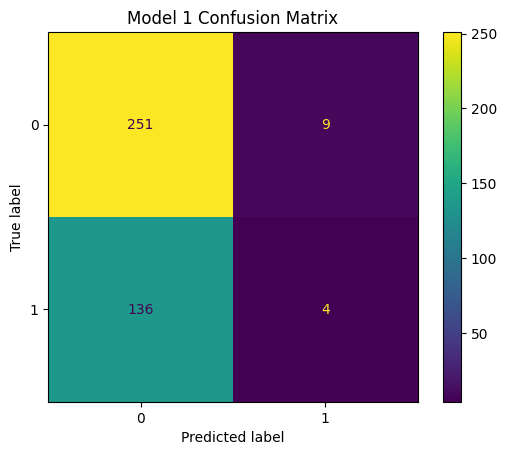

In [11]:
ConfusionMatrixDisplay.from_predictions(y_test, pred1)
plt.title("Model 1 Confusion Matrix")
plt.show()

### Interpreting Model 1

After viewing the confusion matrix and the metric table, answer:

1. How many true positives, true negatives, false positives, and false negatives do you observe?
2. What does the model's **precision** mean in the context of customer churn?
3. What does the model's **recall** mean in the context of customer churn?
4. Is the model making more false-positive or false-negative errors?
5. Which type of error would be more costly for a retention campaign?
6. Does accuracy alone give you enough information to judge this model?

# 12. Model 2 — Multiple Logistic Regression

Our second model uses several predictors.

### Numeric variables
- Fill missing values with the median
- Standardize the values

### Categorical variables
- Fill missing values with the most common category
- Convert categories to indicator variables with one-hot encoding

We will combine preprocessing and logistic regression in one **Pipeline**.


In [12]:
numeric_features = [
    "tenure_months",
    "monthly_charge",
    "support_tickets",
    "usage_change_pct"
]

categorical_features = [
    "contract_type",
    "autopay"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

model2 = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("logistic", LogisticRegression(max_iter=1000))
])

model2.fit(X_train, y_train)

print("Model 2 trained successfully.")

Model 2 trained successfully.


## Why Use a Pipeline?

The pipeline helps prevent **data leakage**.

The imputer, scaler, and encoder are learned from the **training data**.

Then those learned transformations are applied to the test data.

# 13. Evaluate Model 2


In [13]:
prob2 = model2.predict_proba(X_test)[:, 1]
pred2 = model2.predict(X_test)

classification_metrics(y_test, pred2, prob2)

Accuracy     0.715
Precision    0.623
Recall       0.471
F1           0.537
ROC_AUC      0.754
dtype: float64

In [14]:
print(classification_report(y_test, pred2, digits=3))

              precision    recall  f1-score   support

           0      0.748     0.846     0.794       260
           1      0.623     0.471     0.537       140

    accuracy                          0.715       400
   macro avg      0.685     0.659     0.665       400
weighted avg      0.704     0.715     0.704       400



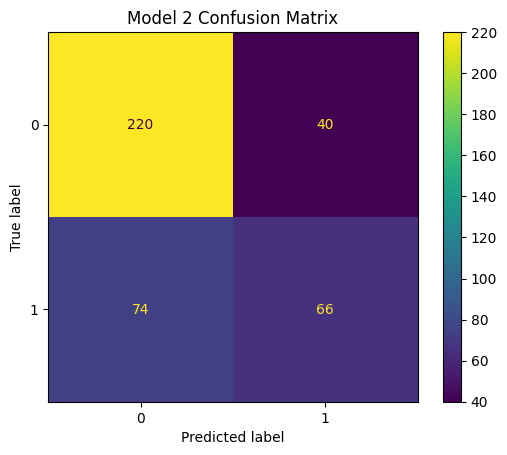

In [15]:
ConfusionMatrixDisplay.from_predictions(y_test, pred2)
plt.title("Model 2 Confusion Matrix")
plt.show()

# 14. Compare Model 1 and Model 2


In [16]:
comparison = pd.DataFrame({
    "Model 1: Support Tickets Only": classification_metrics(y_test, pred1, prob1),
    "Model 2: Multiple Predictors": classification_metrics(y_test, pred2, prob2)
}).T

comparison

,Accuracy,Precision,Recall,F1,ROC_AUC
Model 1: Support Tickets Only,0.638,0.308,0.029,0.052,0.518
Model 2: Multiple Predictors,0.715,0.623,0.471,0.537,0.754


### Discussion
- Which model has higher accuracy?
- Which has higher recall?
- Which has higher precision?
- Which has higher ROC-AUC?
- Does the more complicated model win on every metric?
- Which metric should matter most to a business?

# 15. Accuracy Can Be Misleading

Suppose 1,000 transactions contain:
- 990 legitimate
- 10 fraudulent

A model predicts **everything is legitimate**.

Accuracy = 99%

But the model detects **zero fraud cases**.

This is why classification requires more than accuracy.


In [17]:
majority_prediction = np.zeros_like(y_test)

print("Always-predict-0 accuracy:",
      round(accuracy_score(y_test, majority_prediction), 3))
print("Always-predict-0 recall:",
      round(recall_score(y_test, majority_prediction, zero_division=0), 3))

Always-predict-0 accuracy: 0.65
Always-predict-0 recall: 0.0


# 16. Classification Thresholds

The default threshold is usually 0.50.

But it does **not** have to be 0.50.

Let's compare:
- 0.30
- 0.50
- 0.70


In [18]:
def metrics_at_threshold(y_true, probabilities, threshold):
    y_pred_threshold = (probabilities >= threshold).astype(int)
    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, y_pred_threshold),
        "Precision": precision_score(y_true, y_pred_threshold, zero_division=0),
        "Recall": recall_score(y_true, y_pred_threshold, zero_division=0),
        "F1": f1_score(y_true, y_pred_threshold, zero_division=0)
    }

threshold_results = pd.DataFrame([
    metrics_at_threshold(y_test, prob2, 0.30),
    metrics_at_threshold(y_test, prob2, 0.50),
    metrics_at_threshold(y_test, prob2, 0.70)
])

threshold_results.round(3)

,Threshold,Accuracy,Precision,Recall,F1
0,0.3,0.650,0.500,0.779,0.609
1,0.5,0.715,0.623,0.471,0.537
2,0.7,0.700,0.917,0.157,0.268


## What Usually Happens When We Change the Threshold?

### Lower threshold
More observations are classified as positive.

This often:
- increases recall
- decreases precision
- creates more false positives

### Higher threshold
Fewer observations are classified as positive.

This often:
- increases precision
- decreases recall
- creates more false negatives

The "best" threshold depends on the **decision context**.

In [20]:
feature_names = model2.named_steps["preprocess"].get_feature_names_out()
coefs = model2.named_steps["logistic"].coef_[0]

coef_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefs,
    "Odds_Ratio": np.exp(coefs)
}).sort_values("Coefficient", ascending=False)

coef_table.round(3)

,Feature,Coefficient,Odds_Ratio
2,num__support_tickets,0.444,1.559
1,num__monthly_charge,0.301,1.352
6,cat__autopay_Yes,-0.508,0.602
3,num__usage_change_pct,-0.545,0.580
0,num__tenure_months,-0.619,0.539
4,cat__contract_type_One year,-0.921,0.398
5,cat__contract_type_Two year,-1.422,0.241


# 17. Week 4 Takeaways

### Week 3
**X → Linear Regression → Continuous Prediction**

### Week 4
**X → Logistic Regression → Probability → Threshold → Class**

### Key Ideas
- Logistic regression estimates probabilities.
- The threshold converts probabilities into classes.
- Accuracy alone is often insufficient.
- Precision and recall describe different types of performance.
- Changing the threshold changes the trade-off between false positives and false negatives.
- ROC-AUC evaluates ranking performance across thresholds.
- The business context determines which errors matter most.

### Next Week
**Cross-Validation, Regularization & Features**


# Reflection Questions

1. Why does logistic regression predict a probability instead of directly predicting a class?
2. What is the practical meaning of a classification threshold?
3. Give a business situation where recall matters more than precision.
4. Give a business situation where precision matters more than recall.
5. Why can a model with high accuracy still be a poor model?
6. What did Model 2 gain by using more predictors than Model 1?
7. How could classification be used inside the final self-driving project?